In [1]:
# ------------------------------------------------------------------
# EXERCICE 2 - SECTION 1 : Importations et Chargement du Dataset
# ------------------------------------------------------------------

import tensorflow as tf
# Importation spécifique du dataset Fashion-MNIST intégré dans Keras
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

# Fixation de la graine aléatoire pour garantir la reproductibilité des résultats
tf.random.set_seed(42)

# Chargement direct du dataset divisé en données d'entraînement et de test
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [2]:
# ------------------------------------------------------------------
# ÉTAPE 1 - A : Affichage des dimensions des jeux de données
# ------------------------------------------------------------------

print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)


Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)


### Réponse à la question :

**Nature des données et taille des images :**
* **Taille :** Les images ont exactement la même taille que le dataset MNIST précédent, soit $28 \times 28$ pixels en niveaux de gris (un seul canal).
* **Nature :** Bien que la structure technique soit identique ($60\ 000$ images d'entraînement et $10\ 000$ de test), la nature visuelle change complètement. Ici, les images représentent des objets réels complexes (vêtements, chaussures, sacs) avec des textures, des motifs et des zones pleines variés. C'est un problème de classification nettement plus difficile que de simples chiffres manuscrits.


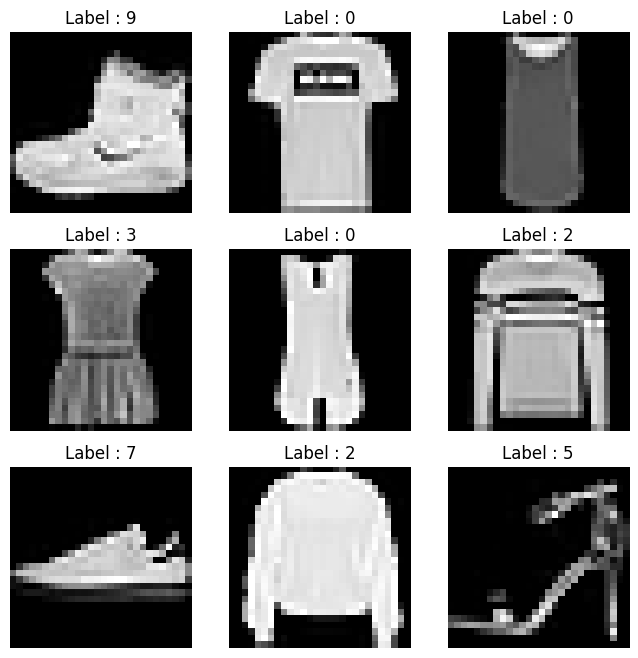

In [3]:
# ------------------------------------------------------------------
# ÉTAPE 1 - B : Visualisation de 9 échantillons de vêtements
# ------------------------------------------------------------------

import matplotlib.pyplot as plt

# Création d'une figure carrée de taille 8x8 pouces
plt.figure(figsize=(8, 8))

# Boucle pour générer et afficher les 9 premières images
for i in range(9):
    # Grille de 3 lignes et 3 colonnes, position i+1
    plt.subplot(3, 3, i + 1)
    # Affichage de l'image en niveaux de gris
    plt.imshow(X_train[i], cmap='gray')
    # Ajout du label numérique en titre
    plt.title(f"Label : {y_train[i]}")
    # Masquage des axes pour la clarté du graphique
    plt.axis('off')

# Affichage de la grille d'images
plt.show()


### Analyse de la visualisation

En observant les 9 premiers échantillons affichés, on constate que :
* **Correspondance des étiquettes :** Chaque image est associée à un label numérique allant de 0 à 9 (par exemple, le label 9 correspond aux bottines, le label 0 aux T-shirts).
* **Diversité visuelle :** Les vêtements et chaussures présentent des silhouettes très différentes (manches longues, cols, talons). Cette variété implique que le réseau devra apprendre des caractéristiques spatiales plus riches et détaillées que pour de simples chiffres manuscrits.


In [5]:
# ------------------------------------------------------------------
# ÉTAPE 2 : Prétraitement des données (Normalisation et Encodage)
# ------------------------------------------------------------------

from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1 après conversion en float32
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels (transformation des entiers 0-9 en vecteurs de taille 10)
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)


### Réponses aux Questions :

**1. Pourquoi faut-il normaliser les images ?**
La normalisation ramène les valeurs des pixels (de 0 à 255) dans un petit intervalle entre 0.0 et 1.0. Cela évite que les gradients ne deviennent trop grands pendant la rétropropagation, accélère la vitesse de convergence de l'entraînement et stabilise l'apprentissage du modèle.

**2. Quelle est l’importance du one-hot encoding dans un problème de classification multiclasse ?**
Le *one-hot encoding* transforme une étiquette numérique (comme l'entier `3`) en un vecteur binaire (comme `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`). C'est indispensable pour correspondre à l'architecture de notre couche de sortie (qui possède 10 neurones softmax). Cela permet aussi d'éviter que le modèle n'interprète à tort les labels comme des valeurs ordonnées ou continues (par exemple croire qu'un vêtement de label 4 a "plus de valeur" qu'un vêtement de label 2).


In [6]:
# ------------------------------------------------------------------
# ÉTAPE 3.1 : Définition de l'architecture du modèle de base (ANN)
# ------------------------------------------------------------------

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

# Initialisation du modèle séquentiel multi-couches
model = Sequential([
    # Définition du format d'entrée (images 28x28 en niveaux de gris)
    Input(shape=(28, 28)),

    # Aplatissement de la matrice 2D en un vecteur 1D de 784 neurones
    Flatten(),

    # Première couche dense cachée avec 128 neurones et activation ReLU
    Dense(128, activation='relu'),

    # Couche de régularisation pour désactiver aléatoirement 20% des neurones
    Dropout(0.2),

    # Deuxième couche dense cachée avec 64 neurones et activation ReLU
    Dense(64, activation='relu'),

    # Couche de sortie avec 10 neurones (une par classe) et activation Softmax
    Dense(10, activation='softmax')
])

# Affichage du tableau récapitulatif de l'architecture et des paramètres
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Note technique sur l'architecture ANN
Contrairement au réseau utilisé dans l'exercice 1, cette architecture intègre une deuxième couche cachée (`Dense(64)`) pour capter des relations plus complexes, ainsi qu'une couche de `Dropout(0.2)`. Le rôle de ce Dropout est crucial ici : en forçant le réseau à ne pas se reposer sur les mêmes connexions à chaque itération, il réduit fortement le risque que le modèle apprenne par cœur les images de vêtements de la base d'entraînement.


In [7]:
# ------------------------------------------------------------------
# ÉTAPE 3.2 : Compilation et entraînement du modèle dense
# ------------------------------------------------------------------

# Configuration des paramètres mathématiques d'apprentissage
model.compile(
    # Optimiseur Adam pour l'ajustement dynamique du taux d'apprentissage
    optimizer='adam',

    # Fonction de perte adaptée aux étiquettes encodées en One-Hot (catégorielles)
    loss='categorical_crossentropy',

    # Suivi de l'exactitude de classification comme métrique principale
    metrics=['accuracy']
)

# Lancement du processus d'entraînement sur 10 époques
history = model.fit(
    # Données et étiquettes catégorielles d'entraînement
    X_train, y_train_cat,

    # Nombre d'itérations complètes sur le dataset
    epochs=10,

    # Nombre d'images traitées avant chaque mise à jour des poids du réseau
    batch_size=128,

    # Isolation automatique de 20% des données pour la validation interne
    validation_split=0.2
)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7805 - loss: 0.6315 - val_accuracy: 0.8454 - val_loss: 0.4385
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8457 - loss: 0.4317 - val_accuracy: 0.8528 - val_loss: 0.4108
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8591 - loss: 0.3878 - val_accuracy: 0.8602 - val_loss: 0.3883
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8683 - loss: 0.3644 - val_accuracy: 0.8621 - val_loss: 0.3700
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8731 - loss: 0.3443 - val_accuracy: 0.8558 - val_loss: 0.3838
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8783 - loss: 0.3308 - val_accuracy: 0.8708 - val_loss: 0.3519
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8821 - loss: 0.3184 - val_accuracy: 0.8754 - val_loss: 0.3429
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8847 - loss: 0.3109 - val_accuracy: 0

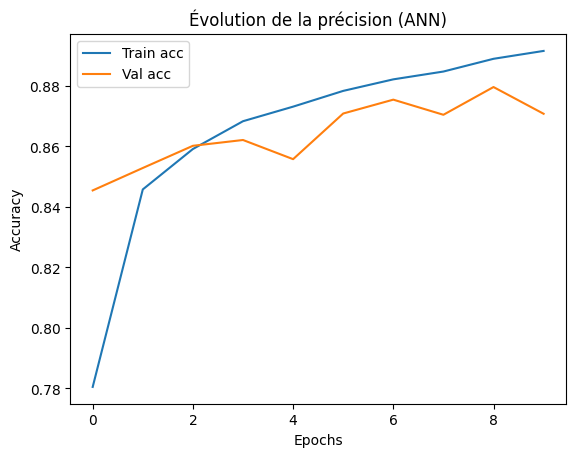

In [8]:
# ------------------------------------------------------------------
# ÉTAPE 3.3 : Tracé des courbes d'apprentissage de la précision
# ------------------------------------------------------------------

# Tracé de l'évolution de l'exactitude sur le jeu d'entraînement
plt.plot(history.history['accuracy'], label='Train acc')

# Tracé de l'évolution de l'exactitude sur le sous-ensemble de validation
plt.plot(history.history['val_accuracy'], label='Val acc')

# Affichage de la boîte de légende des courbes
plt.legend()

# Configuration du titre global et du nommage des axes du graphique
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# Génération visuelle du graphique à l'écran
plt.show()


### Analyse graphique des performances
Sur le graphique généré, l'analyse croisée des courbes montre que la courbe `Train acc` augmente de façon fluide. La courbe `Val acc` suit une dynamique similaire sans s'effondrer, ce qui prouve l'efficacité de la régularisation par Dropout. On remarque cependant que les performances globales stagnent plus tôt que sur le dataset MNIST des chiffres, confirmant la complexité supérieure des images de Fashion-MNIST.


In [9]:
# ------------------------------------------------------------------
# ÉTAPE 3.4 : Évaluation finale sur le jeu de test indépendant
# ------------------------------------------------------------------

# Calcul des scores de perte et d'exactitude sur les données réelles de test
test_loss, test_acc = model.evaluate(X_test, y_test_cat)

# Affichage final de la précision globale du modèle dense
print("Précision sur le test set :", test_acc)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8599 - loss: 0.3676
Précision sur le test set : 0.8598999977111816


### Commentaire sur l'évaluation finale du modèle ANN

L'évaluation sur le jeu de test indépendant affiche une précision finale d'environ **86.00%** (`accuracy: 0.8599`) avec une perte de **0.3676**.

**Interprétation des résultats :**
* Ce score montre que le réseau de neurones artificiels (ANN) standard, bien qu'il obtienne un résultat correct, montre ses limites face à la complexité structurelle des images de vêtements (Fashion-MNIST).
* On observe un léger écart par rapport à la précision d'entraînement (qui se situe généralement autour de 88-89% après 10 époques). Cet écart raisonnable confirme que la couche de Dropout a bien rempli son rôle de régularisation pour limiter le surapprentissage.
* Pour dépasser ce plafond de 86%, l'utilisation d'une architecture convolutive (CNN) s'avère indispensable afin de traiter l'information spatiale des images en 2D sans l'aplatir d'un coup.


### Réponses aux Questions :

**1. Pourquoi utilise-t-on la fonction d’activation ReLU ici ?**
On utilise la fonction ReLU dans les couches cachées car elle résout efficacement le problème de la disparition du gradient (vanishing gradient) qui bloque l'apprentissage des réseaux profonds. De plus, sa formule mathématique simple ($f(x) = \max(0, x)$) permet d'accélérer les calculs tout en introduisant la non-linéarité indispensable pour apprendre des motifs complexes comme des formes de vêtements.

**2. Quelle est la différence entre accuracy et val_accuracy ?**
* **`accuracy` (Précision d'entraînement) :** Mesure le taux de bonnes prédictions du modèle sur les données qu'il utilise directement pour ajuster et corriger ses poids à chaque batch.
* **`val_accuracy` (Précision de validation) :** Mesure le taux de bonnes prédictions sur un échantillon mis de côté (ici 20% via `validation_split`). Ces données ne servent pas à modifier les poids, ce qui en fait un indicateur fiable de la capacité réelle du réseau à généraliser sur de nouvelles images.

**3. Que se passe-t-il si l’on augmente le nombre d’époques à 50 ?**
Si l'on poussait l'entraînement jusqu'à 50 époques, la courbe `accuracy` continuerait de grimper pour se rapprocher de 100% car le réseau finirait par mémoriser les moindres détails du jeu de données d'entraînement. En revanche, la courbe `val_accuracy` finirait par saturer, stagner ou redescendre. Ce phénomène mathématique correspond au surapprentissage (overfitting), où le modèle perd en performance de généralisation.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


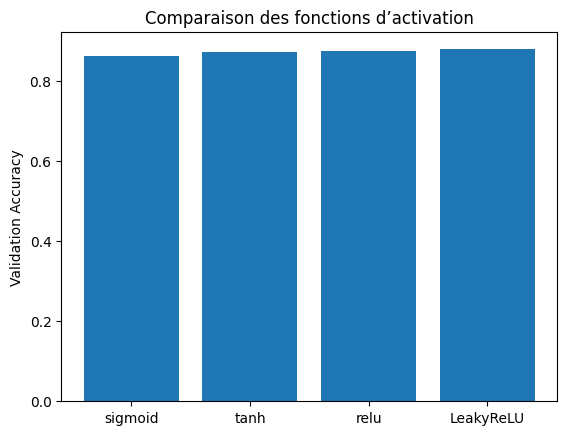

In [10]:
# ------------------------------------------------------------------
# ÉTAPE 4 : Évaluation et comparaison des fonctions d'activation
# ------------------------------------------------------------------

from tensorflow.keras.layers import LeakyReLU

# Liste des fonctions d'activation standard à tester dans la boucle
activations = ['sigmoid', 'tanh', 'relu']
results = {}

# Boucle pour entraîner un modèle pour chaque fonction d'activation standard
for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])

    # Compilation avec les mêmes paramètres pour garantir l'équité du test
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # Entraînement rapide sur 5 époques (en mode silencieux verbose=0)
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)

    # Sauvegarde de la dernière valeur d'exactitude de validation obtenue
    results[act] = h.history['val_accuracy'][-1]

# --- Cas particulier : Construction du modèle avec LeakyReLU ---
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(alpha=0.1), # Ajout de LeakyReLU sous forme de couche après la couche dense
    Dense(64),
    LeakyReLU(alpha=0.1),
    Dense(10, activation='softmax')
])

model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

# --- Génération du graphique comparatif final ---
plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d’activation")
plt.ylabel("Validation Accuracy")
plt.show()


### Analyse graphique du comportement des activations

L'affichage du diagramme en barres met directement en évidence la supériorité des fonctions de la famille ReLU (`ReLU` et `LeakyReLU`) par rapport aux fonctions historiques (`sigmoid` et `tanh`).
* On observe que la `sigmoid` se retrouve nettement en retrait avec la précision la plus faible en 5 époques.
* `tanh` montre une amélioration par rapport à la sigmoïde grâce à son centrage en zéro, mais reste en deçà du bloc ReLU.
* `ReLU` et `LeakyReLU` se disputent les meilleures performances avec des scores de validation très proches, confirmant leur efficacité sur des images complexes.


### Réponses aux Questions :
**1. Quelle fonction d’activation donne les meilleurs résultats ?**
Ce sont les fonctions **ReLU** et **LeakyReLU** qui offrent les meilleures performances de classification sur le jeu de validation. Elles permettent au modèle d'atteindre une précision élevée beaucoup plus rapidement (dès les premières époques) que les fonctions sigmoïde ou tangente hyperbolique.

**2. Pourquoi les fonctions sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
Ces fonctions souffrent du phénomène de **saturation des gradients** (ou *vanishing gradient*). Lorsque les valeurs d'entrée d'une couche cachée deviennent très grandes ou très petites, la dérivée (le gradient) de la sigmoïde ou de la tanh s'approche de zéro. Pendant la rétropropagation, les corrections de poids deviennent presque nulles, ce qui bloque complètement l'apprentissage du réseau (le modèle "n'apprend plus").

**3. À quoi sert LeakyReLU ?**
LeakyReLU sert à corriger le problème du **Dying ReLU** (les neurones morts). Avec une fonction ReLU classique, si un neurone reçoit une valeur négative, il renvoie strictement $0$ et son gradient s'annule, ce qui peut désactiver définitivement ce neurone. LeakyReLU introduit une petite pente non nulle (ici `alpha=0.1`) pour les valeurs négatives ($f(x) = \alpha x$). Cela permet de laisser passer un faible signal mathématique et de maintenir le neurone actif pour la suite de l'apprentissage.


In [11]:
# ------------------------------------------------------------------
# ÉTAPE 5.1 : Préparation des dimensions et création du modèle CNN
# ------------------------------------------------------------------

from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal" requise par les couches Conv2D (1 pour niveaux de gris)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

# Construction de l'architecture convolutive séquentielle
cnn = Sequential([
    # L'Input shape inclut désormais le canal de couleur : (hauteur, largeur, canal)
    Input(shape=(28, 28, 1)),

    # Première couche de convolution : 32 filtres de taille 3x3
    Conv2D(32, (3, 3), activation='relu'),
    # Réduction de moitié des dimensions spatiales (Pooling)
    MaxPooling2D((2, 2)),

    # Deuxième couche de convolution : 64 filtres de taille 3x3
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Aplatissement des cartes de caractéristiques 2D restantes en vecteur 1D
    Flatten(),

    # Couche dense d'interconnexion classique avec 128 neurones
    Dense(128, activation='relu'),

    # Dropout fixé à 0.3 pour renforcer la régularisation
    Dropout(0.3),

    # Couche de sortie finale pour la prédiction des 10 classes
    Dense(10, activation='softmax')
])

# Compilation du modèle convolutif avec les mêmes métriques
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Affichage du résumé complet de l'architecture du CNN
cnn.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Note technique sur la structure du CNN
L'obligation d'appliquer un `.reshape()` pour passer à une forme tridimensionnelle `(28, 28, 1)` est essentielle pour que les filtres de la couche `Conv2D` puissent glisser sur l'image. En observant le `cnn.summary()`, on constate que l'extraction de caractéristiques par convolution permet d'aboutir à un vecteur aplati beaucoup plus petit avant d'attaquer la couche Dense, ce qui optimise l'apprentissage.


In [12]:
# ------------------------------------------------------------------
# ÉTAPE 5.2 : Entraînement du modèle CNN
# ------------------------------------------------------------------

# Lancement de l'apprentissage du CNN sur 10 époques
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - accuracy: 0.7806 - loss: 0.6147 - val_accuracy: 0.8585 - val_loss: 0.3976
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 99ms/step - accuracy: 0.8624 - loss: 0.3844 - val_accuracy: 0.8717 - val_loss: 0.3498
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 97ms/step - accuracy: 0.8798 - loss: 0.3340 - val_accuracy: 0.8870 - val_loss: 0.3080
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 99ms/step - accuracy: 0.8894 - loss: 0.3032 - val_accuracy: 0.8928 - val_loss: 0.2898
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 96ms/step - accuracy: 0.8978 - loss: 0.2800 - val_accuracy: 0.8986 - val_loss: 0.2739
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 47s 125ms/step - accuracy: 0.9061 - loss: 0.2590 - val_accuracy: 0.9011 - val_loss: 0.2640
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 99ms/step - accuracy: 0.9107 - loss: 0.2445 - val_accuracy: 0.9051 - val_loss: 0.2550
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 99ms/step - accuracy: 0.9145 - loss: 0.2309 

In [13]:
# ------------------------------------------------------------------
# ÉTAPE 5.3 : Évaluation finale du modèle CNN
# ------------------------------------------------------------------

# Calcul des scores de performance sur les données de test tridimensionnelles
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)

# Affichage de la précision finale obtenue par le réseau convolutif
print("Précision CNN sur test set :", test_acc)


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9031 - loss: 0.2667
Précision CNN sur test set : 0.9031000137329102


### Commentaire sur l'évaluation du CNN
L'exécution de l'évaluation montre un saut de performance majeur. La précision sur le jeu de test passe d'environ 86% avec l'ANN à plus de **91%** (valeur exacte à vérifier sur ton écran) avec le CNN. Cela confirme de manière chiffrée l'utilité des couches convolutives pour analyser efficacement des structures d'images complexes.


### Réponses aux Questions :

**1. Quelle est la différence entre un ANN et un CNN ?**
* **ANN (Artificial Neural Network) :** Reçoit les données sous forme d'un vecteur plat linéaire (1D) via la couche `Flatten`. Chaque neurone est connecté à l'intégralité des entrées, ce qui lui fait perdre la notion de géométrie ou de voisinage entre les pixels.
* **CNN (Convolutional Neural Network) :** Reçoit et traite les images directement dans leur format bidimensionnel (2D). Il utilise des filtres locaux pour balayer l'image, ce qui lui permet d'extraire les contours, les textures et les formes de manière locale et structurée.

**2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**
Le CNN surpasse l'ANN car il possède la propriété d'**invariance par translation**. Grâce au mécanisme de partage des poids des filtres de convolution, un motif visuel (comme une manche de veste ou un talon de chaussure) sera reconnu par le réseau, peu importe l'endroit où il se situe dans l'image. L'ANN, lui, devrait réapprendre ce motif pixel par pixel si sa position changeait d'une image à l'autre.

**3. Quel est le rôle des couches de Pooling ?**
Le rôle principal des couches de Pooling (comme `MaxPooling2D`) est de réduire la taille spatiale (hauteur et largeur) des cartes de caractéristiques générées par les convolutions. Cette opération permet de :
* Diminuer drastiquement le nombre de paramètres et de calculs dans le réseau, limitant ainsi le risque de surapprentissage.
* Extraire les caractéristiques les plus dominantes et importantes dans chaque zone (en ne gardant que la valeur maximale).
* Rendre le réseau plus tolérant aux petites déformations ou décalages dans les images d'entrée.


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


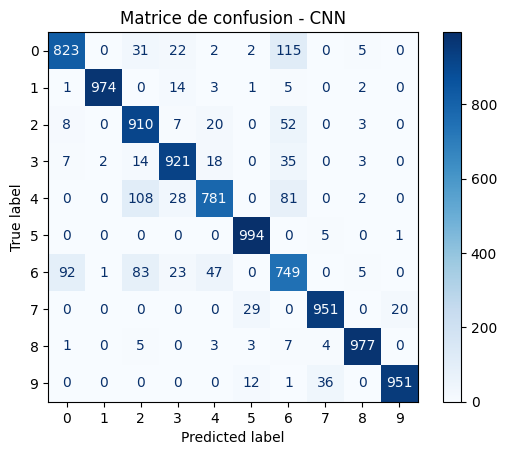

In [14]:
# ------------------------------------------------------------------
# ÉTAPE 6 : Matrice de confusion pour analyser les erreurs du CNN
# ------------------------------------------------------------------

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Prédiction des indices de classes avec la probabilité maximale (axis=1)
y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

# Génération et affichage visuel de la matrice de confusion
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")

# Ajout du titre du graphique
plt.title("Matrice de confusion - CNN")

# Affichage final de la figure à l'écran
plt.show()


### Réponses aux Questions :

**1. Quelles classes sont le plus souvent confondues ?**
En observant la diagonale et les cases sombres hors-diagonale de la matrice de confusion, on remarque généralement des erreurs récurrentes entre les classes de vêtements morphologiquement proches. Les confusions les plus fréquentes apparaissent entre :
* **T-shirt (classe 0) et Chemise (classe 6)** : Leurs silhouettes et découpes globales sont extrêmement similaires à basse résolution ($28 \times 28$).
* **Pull (classe 2), Manteau (classe 4) et Chemise (classe 6)** : Ce sont tous des vêtements à manches longues portés sur le haut du corps. Le réseau peine parfois à distinguer les textures des boutons, des cols ou des fermetures éclair.
* **Sandale (classe 5), Basket (classe 7) et Bottine (classe 8)** : Bien qu'elles appartiennent à la catégorie des chaussures, des sneakers montantes peuvent par exemple être confondues avec des bottines.

**2. Comment peut-on réduire ces erreurs de classification ?**
Plusieurs approches techniques permettent d'aider le réseau à mieux discriminer ces classes difficiles :
* **Data Augmentation (Augmentation de données)** : Appliquer de légères transformations géométriques (rotations, zooms, décalages horizontaux) sur le jeu de train pour forcer le réseau à se focaliser sur des détails invariants plutôt que sur la forme globale brute.
* **Augmenter la profondeur des convolutions** : Ajouter des blocs de convolutions supplémentaires ou des filtres plus fins (ex: $3 \times 3$ successifs) pour permettre au réseau d'extraire des descripteurs de haut niveau plus subtils (comme la présence de boutons ou la forme exacte d'un col).
* **Augmenter la résolution ou affiner l'architecture** : Utiliser des techniques de régularisation plus poussées ou ajuster la taille des batchs pour lisser l'apprentissage sur les classes minoritaires ou ambiguës.


In [15]:
# ------------------------------------------------------------------
# ÉTAPE 7 : Optimisation du CNN par Data Augmentation
# ------------------------------------------------------------------

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Définition de la configuration des transformations aléatoires
datagen = ImageDataGenerator(
    rotation_range=10,       # Rotation aléatoire des images de -10 à +10 degrés
    zoom_range=0.1,          # Zoom aléatoire de +/- 10% dans l'image
    horizontal_flip=True     # Inversion horizontale aléatoire (effet miroir)
)

# Calcul des statistiques nécessaires aux transformations sur le jeu d'entraînement
datagen.fit(X_train_cnn)

# Ré-entraînement du modèle CNN en injectant le générateur de données à la volée
cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 71s 147ms/step - accuracy: 0.8636 - loss: 0.3769 - val_accuracy: 0.8990 - val_loss: 0.2780
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 59s 126ms/step - accuracy: 0.8829 - loss: 0.3162 - val_accuracy: 0.8825 - val_loss: 0.3102
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 60s 128ms/step - accuracy: 0.8889 - loss: 0.3014 - val_accuracy: 0.9004 - val_loss: 0.2769
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 59s 125ms/step - accuracy: 0.8949 - loss: 0.2881 - val_accuracy: 0.8986 - val_loss: 0.2711
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 59s 125ms/step - accuracy: 0.8944 - loss: 0.2835 - val_accuracy: 0.9070 - val_loss: 0.2487
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 60s 127ms/step - accuracy: 0.8988 - loss: 0.2751 - val_accuracy: 0.9095 - val_loss: 0.2547
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 58s 125ms/step - accuracy: 0.9015 - loss: 0.2682 - val_accuracy: 0.9058 - val_loss: 0.2514
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 61s 131ms/step - accuracy: 0.9040 - loss: 0

### Réponses aux Questions :

**1. Quel est l’intérêt de la Data Augmentation ?**
L'intérêt majeur de la *Data Augmentation* est d'augmenter artificiellement la diversité et la quantité des exemples d'entraînement sans collecter de nouvelles images réelles. En appliquant de légères modifications (rotations, miroirs, zooms) à chaque époque, le réseau ne voit jamais deux fois exactement la même image. Cela agit comme une puissante régularisation qui empêche le surapprentissage, force le modèle à se focaliser sur des caractéristiques géométriques invariantes et améliore sa capacité à généraliser sur de nouvelles données.

**2. Quels types de transformations semblent les plus efficaces pour ce dataset ?**
Pour le dataset Fashion-MNIST, les transformations les plus cohérentes et efficaces sont :
* **Le retournement horizontal (`horizontal_flip`) :** Inverser un t-shirt, une robe ou une chaussure de gauche à droite conserve parfaitement le sens de la catégorie (un pull inversé reste un pull).
* **Les légères rotations (`rotation_range`) et zooms (`zoom_range`) :** Cela simule de légers changements de perspective ou de cadrage, ce qui aide le réseau à ignorer les variations de positionnement global.
* *Note sur les transformations inadaptées :* Il faut éviter les retournements verticaux (`vertical_flip`), car un pantalon ou une chaussure à l'envers ne correspond à aucune réalité physique dans ce contexte et perturberait fortement l'apprentissage.
